# Thực hành: chẩn đoán ung thư vú bằng SVM

*Bài 7, mục 7.2.* Bộ dữ liệu **Breast Cancer Wisconsin (Diagnostic)** có sẵn trong scikit-learn: 569 khối u, 30 đặc trưng số tính từ ảnh chụp tế bào (bán kính, kết cấu, chu vi, diện tích, độ nhẵn, … mỗi đại lượng có giá trị trung bình, sai số chuẩn và giá trị lớn nhất). Nhãn: `0` = ác tính (malignant), `1` = lành tính (benign).

## 1. Đọc và khám phá dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
print('Kích thước:', X.shape)
print('Tên lớp:', [str(name) for name in cancer.target_names], ' số mẫu mỗi lớp:', np.bincount(y))
pd.DataFrame(X, columns=cancer.feature_names).iloc[:, :6].describe().round(2)

Kích thước: (569, 30)
Tên lớp: ['malignant', 'benign']  số mẫu mỗi lớp: [212 357]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


Thang đo các đặc trưng chênh lệch rất lớn (`mean area` hàng trăm, `mean smoothness` khoảng 0.1): cần **chuẩn hóa** trước khi dùng SVM.

## 2. SVM tuyến tính với hai đặc trưng (theo giáo trình)

Dùng hai đặc trưng đầu tiên (`mean radius`, `mean texture`) để vẽ được ranh giới trên mặt phẳng.

Số vector hỗ trợ: 152
Độ chính xác trên toàn bộ dữ liệu: 0.889


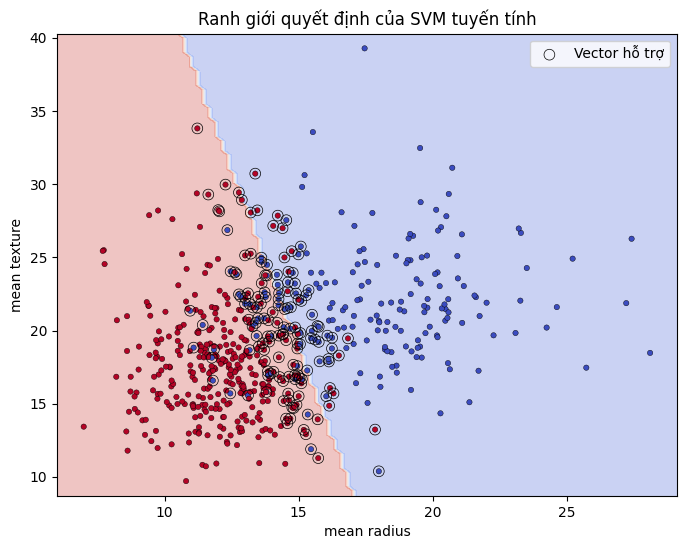

In [2]:
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

X2 = X[:, :2]
feature_names = cancer.feature_names[:2]
model = SVC(kernel='linear', C=1).fit(X2, y)
print('Số vector hỗ trợ:', model.support_vectors_.shape[0])
print('Độ chính xác trên toàn bộ dữ liệu: %.3f' % model.score(X2, y))

fig, ax = plt.subplots(figsize=(8, 6))
DecisionBoundaryDisplay.from_estimator(model, X2, response_method='predict', alpha=0.3, cmap='coolwarm',
                                       xlabel=feature_names[0], ylabel=feature_names[1], ax=ax)
ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap='coolwarm', s=15, edgecolors='k', linewidths=0.3)
ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=60, facecolors='none',
           edgecolors='k', linewidths=0.5, label='Vector hỗ trợ')
ax.set_title('Ranh giới quyết định của SVM tuyến tính'); ax.legend()
plt.show()

Hai lớp chồng lấn nhiều nên có rất nhiều vector hỗ trợ (các điểm nằm trong lề hoặc bị phân loại sai đều là vector hỗ trợ của SVM lề mềm).

## 3. Dùng đủ 30 đặc trưng: chia dữ liệu, chuẩn hóa

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Huấn luyện:', X_train.shape, ' kiểm tra:', X_test.shape)

Huấn luyện: (455, 30)  kiểm tra: (114, 30)


`Pipeline` gộp chuẩn hóa và mô hình: `StandardScaler` chỉ học trung bình, độ lệch chuẩn từ tập huấn luyện (tránh rò rỉ dữ liệu, Bài 2).

In [4]:
for kernel in ['linear', 'rbf']:
    raw = SVC(kernel=kernel).fit(X_train, y_train)
    scaled = make_pipeline(StandardScaler(), SVC(kernel=kernel)).fit(X_train, y_train)
    print('kernel = %-6s: chưa chuẩn hóa %.4f, đã chuẩn hóa %.4f'
          % (kernel, raw.score(X_test, y_test), scaled.score(X_test, y_test)))

kernel = linear: chưa chuẩn hóa 0.9561, đã chuẩn hóa 0.9737
kernel = rbf   : chưa chuẩn hóa 0.9298, đã chuẩn hóa 0.9825


## 4. Chọn siêu tham số bằng kiểm định chéo

In [5]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), SVC())
param_grid = [{'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10, 100]},
              {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.1, 1]}]
search = GridSearchCV(pipe, param_grid, cv=5)
search.fit(X_train, y_train)
print('Siêu tham số tốt nhất:', search.best_params_)
print('Độ chính xác kiểm định chéo: %.4f' % search.best_score_)

Siêu tham số tốt nhất: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Độ chính xác kiểm định chéo: 0.9802


In [6]:
results = pd.DataFrame(search.cv_results_)
results['kernel'] = results['param_svc__kernel']
results[['kernel', 'param_svc__C', 'param_svc__gamma', 'mean_test_score']].sort_values('mean_test_score', ascending=False).head(8)

,kernel,param_svc__C,param_svc__gamma,mean_test_score
14,rbf,10.00,0.010,0.980220
17,rbf,100.00,0.001,0.978022
1,linear,0.10,NaN,0.978022
0,linear,0.01,NaN,0.973626
13,rbf,10.00,0.001,0.973626
18,rbf,100.00,0.010,0.969231
10,rbf,1.00,0.010,0.969231
2,linear,1.00,NaN,0.967033


## 5. Đánh giá trên tập kiểm tra

In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

best = search.best_estimator_
y_pred = best.predict(X_test)
print('Accuracy: %.4f' % accuracy_score(y_test, y_pred))
print('Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự [malignant, benign]):')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=cancer.target_names, digits=3))
print('ROC-AUC: %.4f' % roc_auc_score(y_test, best.decision_function(X_test)))

Accuracy: 0.9825
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự [malignant, benign]):
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant      0.976     0.976     0.976        42
      benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114

ROC-AUC: 0.9977


`decision_function` trả về $f(\mathbf{x}) = \mathbf{w}^T\phi(\mathbf{x}) + b$ (không phải xác suất), vẫn dùng được để tính ROC-AUC vì chỉ cần thứ tự điểm số (Bài 4).

Số vector hỗ trợ của mô hình tốt nhất:

In [8]:
svm = best[-1]
print('Số vector hỗ trợ mỗi lớp:', svm.n_support_, ' tổng:', svm.n_support_.sum(), '/', len(y_train))

Số vector hỗ trợ mỗi lớp: [25 27]  tổng: 52 / 455


## 6. Dự đoán cho một khối u mới

In [9]:
new_tumor = X_test[:1]                      # giả sử là dữ liệu của một bệnh nhân mới
label = best.predict(new_tumor)[0]
print('Dự đoán:', cancer.target_names[label], ' (nhãn thật:', cancer.target_names[y_test[0]], ')')
print('f(x) = %.3f' % best.decision_function(new_tumor)[0])

Dự đoán: malignant  (nhãn thật: malignant )
f(x) = -4.521
